# 1D-CNN training

Load the Positive Control spectral window (8800–8835 Å) from the synthetic spectra produced by `01_datagen_windows.ipynb`, run a Bayesian hyperparameter search over a 1D-CNN with MC Dropout, train the best configuration, and evaluate on the held-out test split.

## Setup

In [1]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")

    REPO_ROOT = Path("/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars")

    import subprocess

    subprocess.run(
        [
            "pip",
            "install",
            "-q",
            "numpy",
            "pandas",
            "pyarrow",
            "matplotlib",
            "tqdm",
            "tensorflow==2.20.0",
            "keras-tuner==1.4.7",
            "scikit-learn",
            "visualkeras",
            "pillow",
        ],
        check=True,
    )
else:
    REPO_ROOT = Path.cwd().parents[1]

sys.path.insert(0, str(REPO_ROOT))
print("REPO_ROOT:", REPO_ROOT)

Mounted at /content/drive
REPO_ROOT: /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import src.datavis as datavis
from src.dataset import load_spectra_parquets, prepare_splits, make_tf_datasets
from src.models import HyperTuningBayCNN

## Experimental setup

In [3]:
DATA_DIR    = REPO_ROOT / "data"

# Positive Control
WINDOW_NAME = "positive_control_8800_8835"

RESULTS_DIR = REPO_ROOT / "results" / "windows" / WINDOW_NAME
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FIGURES_DIR = REPO_ROOT / "figures" / "windows" / WINDOW_NAME
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_TARGETS = ("Teff_K", "logg_cgs", "FeH_dex")
BATCH_SIZE = 32

# Hyperparameter search budget
MAX_TRIALS = 20
SEARCH_EPOCHS = 2

# Final training
EPOCHS = 100
PATIENCE = 8

## Load data

In [4]:
# Positive Control
df = pd.read_parquet(DATA_DIR / "spectra_controle_positivo.parquet")
print("shape:", df.shape)
df.head()

shape: (5000, 8)


,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3579.446357,4.763662,-0.147870,0.399860,0.434133,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9989299774169922, 0.9989288449287415, 0.998...","[896114.6875, 896114.125, 896113.5, 896112.937..."
1,2976.648214,5.215524,-0.403439,0.109080,0.134776,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9994313716888428, 0.9994310140609741, 0.999...","[501204.09375, 501204.09375, 501204.09375, 501..."
2,3751.436959,4.782187,-0.346634,0.438182,0.444871,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.998831570148468, 0.9988303184509277, 0.9988...","[1011267.6875, 1011266.875, 1011266.125, 10112..."
3,3234.390821,4.971277,0.094085,0.271940,0.281902,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9991707801818848, 0.9991700649261475, 0.999...","[672918.1875, 672918.0, 672917.75, 672917.5, 6..."
4,3384.269202,5.035957,-0.356370,0.289908,0.270179,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9992481470108032, 0.9992473721504211, 0.999...","[729171.8125, 729171.5, 729171.1875, 729170.87..."


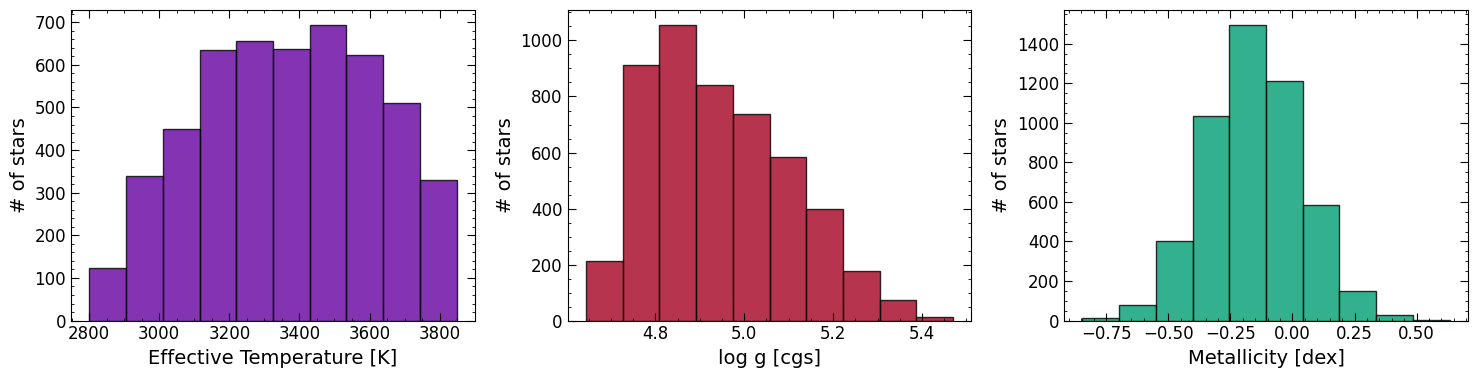

In [5]:
labels = ["Effective Temperature [K]", "log g [cgs]", "Metallicity [dex]"]
colors = ["#65019F", "#A40122", "#009E73"]  # Wong 2011 — colorblind-safe

fig, axes = plt.subplots(1, len(OUTPUT_TARGETS), figsize=(15, 4))
for ax, col, color, label in zip(axes, OUTPUT_TARGETS, colors, labels):
    ax.hist(df[col], bins=10, edgecolor="k", color=color, alpha=0.8)
    ax.set_xlabel(label)
    ax.set_ylabel("# of stars")

fig.tight_layout()
fig.savefig(REPO_ROOT / "figures" / "windows" / "stellar_params_windows_distribution.png", dpi=150, bbox_inches="tight")

## Splits and tf.data pipelines

In [6]:
splits = prepare_splits(df, output_targets=OUTPUT_TARGETS)
train_dataset, validation_dataset, test_dataset = make_tf_datasets(
    splits, batch_size=BATCH_SIZE
)

input_shape = splits.X_train.shape[1:]
print("input_shape:", input_shape)
print(
    "train:",
    splits.X_train.shape,
    "  val:",
    splits.X_val.shape,
    "  test:",
    splits.X_test.shape,
)

input_shape: (3501, 1)
train: (4050, 3501, 1)   val: (450, 3501, 1)   test: (500, 3501, 1)


## Bayesian hyperparameter search

In [7]:
cnn_tuner = HyperTuningBayCNN(
    input_shape=input_shape,
    outputs_list=OUTPUT_TARGETS,
    tuner_directory=RESULTS_DIR,
    project_name="cnn_bay_tuning_" + WINDOW_NAME,
)

best_hps = cnn_tuner.search(
    train_dataset,
    validation_dataset,
    max_trials=MAX_TRIALS,
    search_epochs=SEARCH_EPOCHS,
)
best_hps.values

Trial 20 Complete [00h 00m 31s]
val_loss: 3.613104820251465

Best val_loss So Far: 2.971280813217163
Total elapsed time: 00h 10m 56s


{'conv_blocks': 2,
 'filters_b0_a': 16,
 'kernel_b0_a_ks': 7,
 'filters_b0_b': 80,
 'kernel_b0_b_ks': 3,
 'dropout_rate_conv_b0': 0.30000000000000004,
 'dense_layers': 3,
 'units_dense_0': 256,
 'dropout_rate_dense_0': 0.2,
 'learning_rate': 2.58946845560749e-05,
 'filters_b1_a': 32,
 'kernel_b1_a_ks': 7,
 'filters_b1_b': 16,
 'kernel_b1_b_ks': 9,
 'dropout_rate_conv_b1': 0.0,
 'filters_b2_a': 80,
 'kernel_b2_a_ks': 7,
 'filters_b2_b': 112,
 'kernel_b2_b_ks': 3,
 'dropout_rate_conv_b2': 0.2,
 'units_dense_1': 512,
 'dropout_rate_dense_1': 0.2,
 'units_dense_2': 64,
 'dropout_rate_dense_2': 0.0}

## Train the best model

In [8]:
best_model, history = cnn_tuner.fit_best_model(
    train_dataset,
    validation_dataset,
    epochs=EPOCHS,
    patience=PATIENCE,
)
cnn_tuner.summary()

Epoch 1/100
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - FeH_dex_loss: 0.8945 - Teff_K_loss: 0.6145 - logg_cgs_loss: 0.6103 - loss: 2.1321 - val_FeH_dex_loss: 0.8813 - val_Teff_K_loss: 1.0858 - val_logg_cgs_loss: 1.1092 - val_loss: 3.0180
Epoch 2/100
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - FeH_dex_loss: 0.6206 - Teff_K_loss: 0.2232 - logg_cgs_loss: 0.2752 - loss: 1.1288 - val_FeH_dex_loss: 0.9022 - val_Teff_K_loss: 1.0587 - val_logg_cgs_loss: 1.0912 - val_loss: 2.9913
Epoch 3/100
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - FeH_dex_loss: 0.3842 - Teff_K_loss: 0.1244 - logg_cgs_loss: 0.2144 - loss: 0.7333 - val_FeH_dex_loss: 1.1048 - val_Teff_K_loss: 0.9542 - val_logg_cgs_loss: 1.0120 - val_loss: 3.0125
Epoch 4/100
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - FeH_dex_loss: 0.2053 - Teff_K_loss: 0.0694 - logg_cgs_loss: 0.1748 - loss: 0.4600 - val_FeH_dex_loss: 1.8910 - val_Teff_K_loss: 0.6121 - val_logg_cgs_loss: 0.7030 - val_loss: 3.2431
Epoch 5/100
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/st

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 3501, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 3501, 16)  │        128 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 3501, 80)  │      3,920 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 1750, 80)  │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1750, 80)  │        320 │ max_pooling1d_3[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_mc_dropout… │ (None, 1750, 80)  │          0 │ batch_normalizat… │
│ (SpatialMCDropout)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 1750, 32)  │     17,952 │ spatial_mc_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 1750, 16)  │      4,624 │ conv1d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 875, 16)   │          0 │ conv1d_9[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 875, 16)   │         64 │ max_pooling1d_4[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_mc_dropout… │ (None, 875, 16)   │          0 │ batch_normalizat… │
│ (SpatialMCDropout)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 14000)     │          0 │ spatial_mc_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │  3,584,256 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mc_dropout_1        │ (None, 256)       │          0 │ dense_1[0][0]     │
│ (MCDropout)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 512)       │    131,584 │ mc_dropout_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mc_dropout_2        │ (None, 512)       │          0 │ dense_2[0][0]     │
│ (MCDropout)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │     32,832 │ mc_dropout_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mc_dropout_3        │ (None, 64)        │          0 │ dense_3[0][0]     │
│ (MCDropout)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ FeH_dex (Dense)     │ (None, 1)         │         65 │ mc_dropout_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Teff_K (Dense)      │ (None, 1)         │         65 │ mc_dropout_3[0][

 Total params: 11,327,242 (43.21 MB)

 Trainable params: 3,775,683 (14.40 MB)

 Non-trainable params: 192 (768.00 B)

 Optimizer params: 7,551,367 (28.81 MB)

## Loss curves

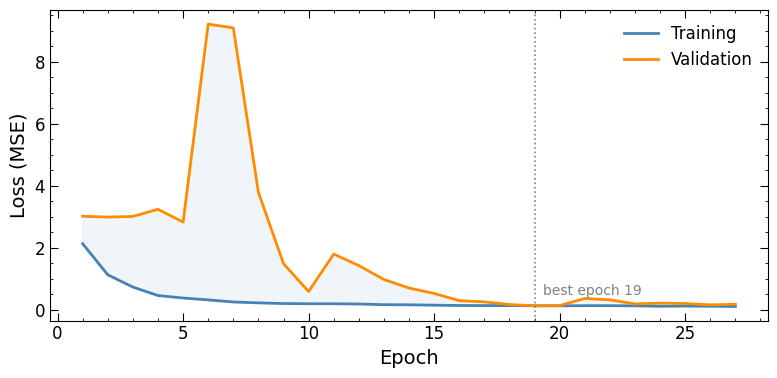

In [9]:
fig, ax = cnn_tuner.plot_losses(show=True)
fig.savefig(FIGURES_DIR / f"{WINDOW_NAME}_losses.png", dpi=150, bbox_inches="tight")

## Evaluation on the test split

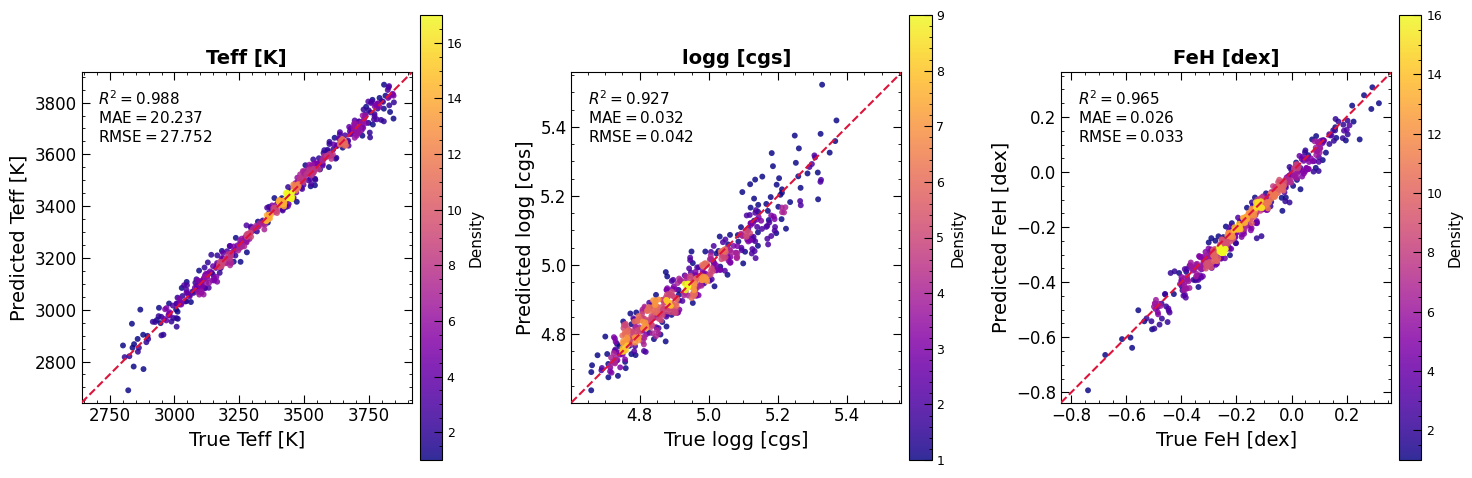

,R2,MAE,MSE,RMSE
Teff [K],0.988,20.237,770.201,27.752
logg [cgs],0.927,0.032,0.002,0.042
FeH [dex],0.965,0.026,0.001,0.033


In [10]:
feature_names = ["Teff [K]","logg [cgs]","FeH [dex]"]

results, fig_axs = cnn_tuner.evaluate(
    test_dataset,
    feature_names=feature_names,
    y_scalers=splits.output_scalers,
    plot=True,
)
fig_eval, _ = fig_axs
fig_eval.savefig(FIGURES_DIR / f"{WINDOW_NAME}_evaluation.png", dpi=150, bbox_inches="tight")
results

In [11]:
# Append window results to comparison CSV — long format (one row per window-parameter combination)
csv_path = REPO_ROOT / "results" / "window_comparison.csv"

results_to_save = results.copy()
results_to_save.insert(0, "window", WINDOW_NAME)

if csv_path.exists():
    results_to_save.to_csv(csv_path, mode="a", header=False, index=True)
else:
    results_to_save.to_csv(csv_path, mode="w", header=True, index=True)

print(f"Results saved to {csv_path}")

Results saved to /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars/results/window_comparison.csv


In [12]:
# Extract and save per-star predictions for residual and scatter analysis
y_true_list = {name: [] for name in OUTPUT_TARGETS}
y_pred_list = {name: [] for name in OUTPUT_TARGETS}

for X_batch, y_batch in test_dataset:
    preds = cnn_tuner.best_model.predict(X_batch, verbose=0)
    for i, name in enumerate(OUTPUT_TARGETS):
        y_true_list[name].extend(y_batch[name].numpy().reshape(-1).tolist())
        if isinstance(preds, dict):
            y_pred_list[name].extend(preds[name].reshape(-1).tolist())
        else:
            y_pred_list[name].extend(preds[:, i].reshape(-1).tolist())

predictions = {}
for i, name in enumerate(OUTPUT_TARGETS):
    predictions[f"{name}_true"] = splits.output_scalers[i].inverse_transform(
        np.array(y_true_list[name]).reshape(-1, 1)
    ).ravel()
    predictions[f"{name}_pred"] = splits.output_scalers[i].inverse_transform(
        np.array(y_pred_list[name]).reshape(-1, 1)
    ).ravel()

predictions_df = pd.DataFrame(predictions)
predictions_df["window"] = WINDOW_NAME
predictions_df.to_parquet(RESULTS_DIR / f"predictions_{WINDOW_NAME}.parquet", index=False)
print(f"Predictions saved: {predictions_df.shape}")
predictions_df.head()

Predictions saved: (500, 7)


,Teff_K_true,Teff_K_pred,logg_cgs_true,logg_cgs_pred,FeH_dex_true,FeH_dex_pred,window
0,3826.799344,3799.761569,4.659666,4.691036,0.028730,-0.048931,positive_control_8800_8835
1,3845.934983,3792.643363,4.728530,4.699879,-0.130968,-0.034388,positive_control_8800_8835
2,3217.752781,3244.918976,5.059535,5.050981,-0.312482,-0.328334,positive_control_8800_8835
3,3736.373730,3784.876205,4.774087,4.792987,-0.320497,-0.364719,positive_control_8800_8835
4,3832.622856,3832.046221,4.708897,4.737629,-0.132907,-0.066863,positive_control_8800_8835


## Save the trained model

In [13]:
cnn_tuner.best_model.save(RESULTS_DIR / f"model_{WINDOW_NAME}.keras")